# DSCI 552 Homework 3


In [25]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = "/content/drive/MyDrive/AReM"
except ImportError:
    DATA_DIR = "../data/AReM"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
import os, re, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

## 1. feature creation/extraction

In [14]:
def load_instance(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            vals = [v for v in re.split(r"[,\s]+", line) if v != ""]
            rows.append([float(v) for v in vals[:7]])
    df = pd.DataFrame(rows, columns=["time"] + SERIES)
    return df

def file_number(fname):
    return int(re.search(r"(\d+)", fname).group(1))

instances = []   # list of dicts: activity, file number, dataframe
for act in ACTIVITIES:
    folder = os.path.join(DATA_DIR, act)
    files = sorted([f for f in os.listdir(folder) if f.endswith(".csv")], key=file_number)
    for f in files:
        df = load_instance(os.path.join(folder, f))
        instances.append({"activity": act, "file": f, "num": file_number(f), "data": df})

print("Total instances:", len(instances))
print(pd.Series([i["activity"] for i in instances]).value_counts().sort_index())
print("\nRows per instance:")
print(pd.Series([len(i["data"]) for i in instances]).value_counts())

Total instances: 88
bending1     7
bending2     6
cycling     15
lying       15
sitting     15
standing    15
walking     15
Name: count, dtype: int64

Rows per instance:
480    87
479     1
Name: count, dtype: int64


In [15]:
instances[0]["data"].head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0.0,39.25,0.43,22.75,0.43,33.75,1.3
1,250.0,39.25,0.43,23.00,0.00,33.00,0.0
2,500.0,39.25,0.43,23.25,0.43,33.00,0.0
3,750.0,39.50,0.50,23.00,0.71,33.00,0.0
4,1000.0,39.50,0.50,24.00,0.00,33.00,0.0


### b. train/testing


In [16]:
def is_test(act, num):
    if act in ("bending1", "bending2"):
        return num in (1, 2)
    return num in (1, 2, 3)

for inst in instances:
    inst["split"] = "test" if is_test(inst["activity"], inst["num"]) else "train"

split_summary = pd.crosstab(pd.Series([i["activity"] for i in instances], name="activity"),
                            pd.Series([i["split"] for i in instances], name="split"), margins=True)
split_summary

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


### c. feature extraction

i. Time-domain features usually used in time series classification include mean, median, minimum, maximum, range, standard deviation, variance, first and third quartiles, interquartile range, skewness, kurtosis, root mean square (RMS), number of peaks, and zero-crossing rate.

https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html


In [17]:
FEATURE_FUNCS = {
    "min":       lambda x: x.min(),
    "max":       lambda x: x.max(),
    "mean":      lambda x: x.mean(),
    "median":    lambda x: x.median(),
    "std":       lambda x: x.std(),
    "1st_quart": lambda x: x.quantile(0.25),
    "3rd_quart": lambda x: x.quantile(0.75),
}

def extract_features(df):
    feats = {}
    for s_idx, s in enumerate(SERIES, start=1):
        for fname, func in FEATURE_FUNCS.items():
            feats[f"{fname}{s_idx}"] = func(df[s])
    return feats

records = []
for idx, inst in enumerate(instances, start=1):
    row = {"Instance": idx}
    row.update(extract_features(inst["data"]))
    row["activity"] = inst["activity"]
    row["split"] = inst["split"]
    records.append(row)

features = pd.DataFrame(records).set_index("Instance")
feature_cols = [c for c in features.columns if c not in ("activity", "split")]
print("Feature matrix shape (instances x features):", features[feature_cols].shape)
features

Feature matrix shape (instances x features): (88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,split
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,0.430,0.322605,0.00,0.5000,4.00,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.0000,1.1200,27.25,38.25,34.311292,35.00,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000,bending1,test
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,0.470,0.289158,0.00,0.5000,2.00,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.0000,1.1450,27.67,38.50,33.024583,33.00,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000,bending1,test
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,0.470,0.338690,0.00,0.5000,6.50,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.0000,0.8300,29.00,38.50,35.588458,36.00,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400,bending1,train
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,0.500,0.630860,0.00,1.1200,8.50,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.4300,1.3000,20.00,38.67,33.493917,35.00,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000,bending1,train
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,0.500,0.405469,0.43,0.7100,3.00,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.4300,1.1200,23.67,37.50,29.857083,30.00,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000,bending1,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,4.260,2.461077,2.87,6.1050,7.33,23.25,15.317854,15.330,2.970440,13.25,17.2700,0.0,9.00,3.227229,3.10,1.647474,2.0500,4.2600,6.33,25.00,15.892146,16.00,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225,walking,train
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,3.900,2.599284,2.49,5.9700,6.25,22.25,15.209771,15.250,2.711022,13.50,17.0000,0.0,9.00,3.277229,3.11,1.500046,2.1700,4.3900,6.25,23.25,15.550458,15.75,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650,walking,train
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,4.135,2.360448,2.49,5.8000,7.00,22.67,15.185729,15.250,2.757604,13.25,17.0000,0.0,8.34,3.028687,2.86,1.665184,1.7900,4.1100,7.00,22.75,15.759542,15.75,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350,walking,train


In [18]:
features.to_csv("arem_time_domain_features.csv")

#### iii. standard deviation of each feature + 90% bootstrap confidence intervals


In [19]:
rng = np.random.default_rng(552)
B = 1000
X = features[feature_cols].to_numpy()
n = X.shape[0]

boot_stds = np.empty((B, X.shape[1]))
for b in range(B):
    idx = rng.integers(0, n, n)
    boot_stds[b] = X[idx].std(axis=0, ddof=1)

std_table = pd.DataFrame({
    "std_estimate": X.std(axis=0, ddof=1),
    "CI_lower_5%": np.percentile(boot_stds, 5, axis=0),
    "CI_upper_95%": np.percentile(boot_stds, 95, axis=0),
}, index=feature_cols)
std_table["CI_width"] = std_table["CI_upper_95%"] - std_table["CI_lower_5%"]
std_table.round(3)

,std_estimate,CI_lower_5%,CI_upper_95%,CI_width
min1,9.570,8.235,10.689,2.454
max1,4.394,3.333,5.305,1.972
mean1,5.336,4.705,5.886,1.181
median1,5.440,4.792,6.009,1.217
std1,1.772,1.572,1.944,0.372
1st_quart1,6.154,5.568,6.634,1.066
3rd_quart1,5.139,4.330,5.861,1.531
min2,0.000,0.000,0.000,0.000
max2,5.063,4.640,5.392,0.752
mean2,1.574,1.393,1.704,0.312


In [20]:
wide = std_table["std_estimate"].copy()
wide.index = pd.MultiIndex.from_tuples(
    [(re.match(r"(.*?)(\d)$", c).group(1), f"series {re.match(r'(.*?)(\d)$', c).group(2)} ({SERIES[int(c[-1])-1]})") for c in wide.index],
    names=["feature", "time series"])
wide.unstack("feature")[list(FEATURE_FUNCS)].round(3)

feature,min,max,mean,median,std,1st_quart,3rd_quart
time series,,,,,,,
series 1 (avg_rss12),9.570,4.394,5.336,5.440,1.772,6.154,5.139
series 2 (var_rss12),0.000,5.063,1.574,1.412,0.884,0.946,2.125
series 3 (avg_rss13),2.956,4.875,4.008,4.036,0.947,4.221,4.172
series 4 (var_rss13),0.000,2.184,1.166,1.146,0.458,0.844,1.553
series 5 (avg_rss23),6.124,5.741,5.676,5.814,1.025,6.096,5.532
series 6 (var_rss23),0.046,2.519,1.155,1.086,0.518,0.759,1.524


#### iv. most important time-domain features

In [21]:
from scipy.stats import f_oneway

train = features[features["split"] == "train"]
f_scores = {}
for col in feature_cols:
    groups = [g[col].values for _, g in train.groupby("activity")]
    f_scores[col] = f_oneway(*groups).statistic

f_df = pd.Series(f_scores).rename("F").to_frame()
f_df["feature"] = [re.match(r"(.*?)(\d)$", c).group(1) for c in f_df.index]
f_summary = f_df.groupby("feature")["F"].agg(["mean", "median"]).sort_values("mean", ascending=False)
f_summary.round(2)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)


,mean,median
feature,,
mean,368.17,307.44
3rd_quart,350.44,297.07
median,317.75,252.83
1st_quart,154.11,135.16
std,109.17,71.92
max,30.03,32.33
min,14.64,16.84


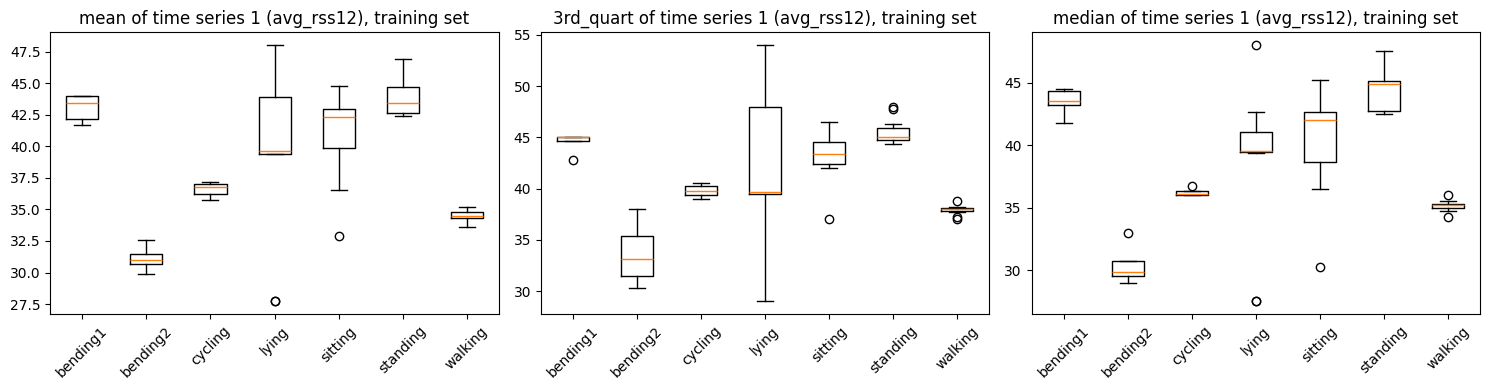

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, ["mean", "3rd_quart", "median"]):
    data = [train[train["activity"] == a][f"{feat}1"] for a in ACTIVITIES]
    ax.boxplot(data, tick_labels=ACTIVITIES)
    ax.set_title(f"{feat} of time series 1 (avg_rss12), training set")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Three most important highest-scoring features: mean, 3rd quartile, and median, which we can see from looking at the three highest mean ANOVA F-scores. These 3 capture the typical value of each signal that depends on the body position which allows the activities to be separated well.

Min and max scored lowest since each depends on a single extreme reading so a spike randomly can alter a lot.

## 2. ISLR 3.7.4

a. Considering the true relationship between X and Y is linear, we would expect the cubic model's training RSS to be lower than or equal to the linear model's as it will fit more closely to the points, including noise. The two models' RSS values also may be equal since the linear model is a special case of the cubic, where the coefficients of the additional terms may be 0 so adding X^2 and X^3 can never increase training RSS. The extra terms could fit some of the noise.

b. When the true relationship is linear, the linear model's test RSS should be lower. This is because the cubic model overfits the noise which adds variance without reducing bias, meaning its test error increases.

c. If the true relationship between X and Y is not linear, the cubic model's training RSS will be lower than or equal to the linear model's. This is because just like my explanation in a, the cubic model can always reduce to the linear model by setting the extra coefficients to 0. Therefore, adding more terms can never increase training RSS.

d. If the true relationship is not linear, we would not have enough information to tell which model's test RSS will be lower. If we know that the true relationship is only slightly nonlinear, then the linear model may still have lower test RSS since its small bias may be less costly than the cubic model's extra variance. If it's very nonlinear, the cubic model's lower bias will outweigh its extra variance, so it will have lower test RSS. This is the bias-variance trade-off, so we would need to have more information about the linearity of the true relationship to pinpoint which effect's larger.